In [1]:
# Import the necessary libraries
from core.glacier import GlacierDynamicsCheckpointed
import torch
from core.inversion import inversion_extent,inversion_thicknes, invert_field
from visualization.plots import  visualize_velocities,plot_loss_components, plot_thickness_divflux_velocities
import matplotlib.pyplot as plt
from core.utils import metrics_to_str,iterations_to_jsonl
from core.cnn_model import CNN
from data.loader import load_geology,load_daily_data
import netCDF4
from config.read_config import parse_arguments
import torch.nn.functional as F
import numpy as np

%matplotlib inline

You are working on cuda device
Using device: cuda


In [2]:
# Create output directory
import os
os.makedirs('results/ela_inversion', exist_ok=True)

def plot_thickness_comparison(H_sim, observation, iteration, save_dir='results/ela_inversion'):
    """
    Plot and save comparison between predicted and observed glacier thickness.
    
    Parameters:
    -----------
    H_sim : torch.Tensor
        Predicted glacier thickness
    observation : torch.Tensor
        Observed glacier thickness
    iteration : int
        Current iteration number
    save_dir : str
        Directory to save the figure
    """
    H_difference = H_sim - observation

    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    # Observed thickness
    im1 = axes[0].imshow(observation.cpu().detach().numpy(), cmap='viridis', aspect='auto')
    axes[0].set_title('Observed Glacier Thickness')
    axes[0].set_xlabel('X')
    axes[0].set_ylabel('Y')
    plt.colorbar(im1, ax=axes[0], label='Thickness (m)')

    # Predicted thickness
    im2 = axes[1].imshow(H_sim.cpu().detach().numpy(), cmap='viridis', aspect='auto')
    axes[1].set_title('Predicted Glacier Thickness')
    axes[1].set_xlabel('X')
    axes[1].set_ylabel('Y')
    plt.colorbar(im2, ax=axes[1], label='Thickness (m)')

    # Difference
    im3 = axes[2].imshow(H_difference.cpu().detach().numpy(), cmap='seismic', aspect='auto')
    axes[2].set_title('Difference (Predicted - Observed)')
    axes[2].set_xlabel('X')
    axes[2].set_ylabel('Y')
    plt.colorbar(im3, ax=axes[2], label='Thickness Difference (m)')

    for ax in axes:
        ax.invert_yaxis()

    plt.tight_layout()
    
    # Save figure
    save_path = os.path.join(save_dir, f'thickness_comparison_iter_{iteration:04d}.png')
    plt.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.close(fig)
    
    # Return statistics
    rmse = torch.sqrt((H_difference**2).mean()).item()
    mean_diff = H_difference.mean().item()
    std_diff = H_difference.std().item()
    
    return rmse, mean_diff, std_diff

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
args = parse_arguments([])  # use defaults


cuda


In [4]:

config = {
"nb_layers": 8,               # Number of convolutional layers
"nb_out_filter": 64,           # Number of output filters for Conv2D
"conv_ker_size": 5,            # Convolution kernel size
"activation": "lrelu",          # Activation function: "relu" or "lrelu"
"dropout_rate": 0.1,           # Dropout rate
}
nb_inputs = 3  # thk, slopsurfx, slopsurfy
nb_outputs = 2  # ubar, vbar
state = torch.load('data/emulator_model.pth', map_location=device, weights_only=False)
model = CNN(nb_inputs, nb_outputs, config).to(device)
model.load_state_dict(state, strict=True)
model.eval()

CNN(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.1, inplace=False)
    (3): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.1, inplace=False)
    (6): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.1, inplace=False)
    (9): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.1, inplace=False)
    (12): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (13): LeakyReLU(negative_slope=0.01)
    (14): Dropout(p=0.1, inplace=False)
    (15): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (16): LeakyReLU(negative_slope=0.01)
    (17): Dropout(p=0.1, inplace=False)
    (18): Conv2d(64, 64, kernel_size=(5, 5), stride=(

## Manifacture

In [5]:
nc = netCDF4.Dataset('./data/geology.nc')
topo = torch.tensor(nc.variables['topg'][:], device=device)
H_init = torch.tensor(nc.variables['surf_1880'][:], device=device)- topo
icemask = torch.tensor(nc.variables['icemask'][:], device=device)
h_init=torch.zeros(topo.shape, device=device)
nc.close()

In [6]:
args.t_start = torch.tensor(2000.0)
args.ttot = torch.tensor(2100.0)
args.vis_freq = 10.0  # Visualize every 1 year
args.cfl=0.2

print(f"Simulation period: {args.t_start.item()} to {args.ttot.item()}")

Simulation period: 2000.0 to 2100.0


In [7]:
glacier_model = GlacierDynamicsCheckpointed(
        topo,h_init, ice_mask=icemask,device=device,args=args,model=model,visualize=False
    )

In [8]:
# True parameters for generating observations
ELA_true = torch.as_tensor(2800.0, device=device)
grad_b_true = torch.as_tensor(0.002, device=device)
b_max_true = torch.as_tensor(1.5, device=device)

print(f"True parameters:")
print(f"  ELA = {ELA_true.item()}")
print(f"  grad_b = {grad_b_true.item()}")
print(f"  b_max = {b_max_true.item()}")

True parameters:
  ELA = 2800.0
  grad_b = 0.0020000000949949026
  b_max = 1.5


In [9]:
# Generate observations using true parameters
print("Generating observations with true parameters...")
H_observation = glacier_model(
    precip_tensor=None,
    T_m_lowest=None,
    T_s=None,
    melt_factor=None,
    smb_method='ELA',
    ELA=ELA_true,
    grad_b=grad_b_true,
    b_max=b_max_true
)
print("Observations generated successfully!")

Generating observations with true parameters...


/home/klleshi/Documents/InvertedGlacierEvolutionModel/core/glacier.py:72: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t_last_update = torch.tensor(self.t_start, device=self.device)


/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:632: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(


Observations generated successfully!


In [10]:
# Save observations
torch.save(H_observation, 'data/H_observation.pt')
print("Observations saved to data/H_observation.pt")

Observations saved to data/H_observation.pt


In [11]:
# Inversion setup - inverting for ELA and grad_b (bounded), b_max fixed
print("\nStarting inversion...")

# Initial guesses
ELA_inv = torch.tensor(3500.0, device=device, requires_grad=True)



print(f"\nInitial guesses:")
print(f"  ELA = {ELA_inv.item()}")

# Load observation
observation = torch.load('data/H_observation.pt', map_location=device)

# Setup optimizer (Option A: parameter groups with smaller lr for grad_b)
optimizer = torch.optim.Adam([
    {"params": [ELA_inv],    "lr": 1},
])

# History tracking
loss_hist = []
ELA_history = []
grad_b_history = []

num_iterations = 1000



for i in range(num_iterations):
    optimizer.zero_grad()

    # Constrain grad_b to physical range

    # Forward pass with current parameter estimates
    H_sim = glacier_model(
        precip_tensor=None,
        T_m_lowest=None,
        T_s=None,
        melt_factor=None,
        smb_method='ELA',
        ELA=ELA_inv,
        grad_b=grad_b_true,  # fixed during inversion
        b_max=b_max_true  # fixed during inversion
    )

    # Compute loss (mean squared error)
    loss = F.mse_loss(H_sim, observation)

    # Backward pass
    loss.backward()

    # torch.nn.utils.clip_grad_norm_([ELA_inv, grad_b_raw], max_norm=1.0)

    # torch.nn.utils.clip_grad_norm_([ELA_inv], max_norm=1.0)
    # torch.nn.utils.clip_grad_norm_([grad_b_raw], max_norm=1.0)  # or a different max_norm


    # Step
    optimizer.step()

    # Record history
    loss_hist.append(loss.item())
    ELA_history.append(ELA_inv.item())

    # Print progress + gradients occasionally
    if (i + 1) % 10 == 0 or i == 0:
        # Plot and save thickness comparison
        rmse, mean_diff, std_diff = plot_thickness_comparison(H_sim, observation, i + 1)
        
        print(
            f"Iter {i+1}/{num_iterations}: loss={loss.item():.6f}, "
        )
        print(f"  dLoss/dELA     = {ELA_inv.grad.item():.6e}")
        print(f"  Thickness RMSE: {rmse:.4f} m")
        print(f"  Difference - Mean: {mean_diff:.4f}, Std: {std_diff:.4f}")

print("\nInversion completed!")
print(f"\nFinal inverted parameters:")
print(f"  ELA = {ELA_inv.item():.2f} (true: {ELA_true.item():.2f})")



Starting inversion...

Initial guesses:
  ELA = 3500.0


/tmp/ipykernel_3352436/1977047627.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  observation = torch.load('data/H_observation.pt', map_location=device)


Iter 1/1000: loss=2799.311035, 
  dLoss/dELA     = 3.853134e-01
  Thickness RMSE: 52.9085 m
  Difference - Mean: -20.8320, Std: 48.6356


Iter 10/1000: loss=2795.736084, 
  dLoss/dELA     = 4.053051e-01
  Thickness RMSE: 52.8747 m
  Difference - Mean: -20.7720, Std: 48.6245


Iter 20/1000: loss=2791.193604, 
  dLoss/dELA     = 4.387599e-01
  Thickness RMSE: 52.8317 m
  Difference - Mean: -20.6975, Std: 48.6095


...

Iter 960/1000: loss=0.000001, 
  dLoss/dELA     = -1.741718e-04
  Thickness RMSE: 0.0011 m
  Difference - Mean: 0.0001, Std: 0.0011


Iter 970/1000: loss=0.000001, 
  dLoss/dELA     = -1.741718e-04
  Thickness RMSE: 0.0011 m
  Difference - Mean: 0.0001, Std: 0.0011


Iter 980/1000: loss=0.000001, 
  dLoss/dELA     = -1.741718e-04
  Thickness RMSE: 0.0011 m
  Difference - Mean: 0.0001, Std: 0.0011


Iter 990/1000: loss=0.000001, 
  dLoss/dELA     = -1.741718e-04
  Thickness RMSE: 0.0011 m
  Difference - Mean: 0.0001, Std: 0.0011


Iter 1000/1000: loss=0.000001, 
  dLoss/dELA     = -1.741718e-04
  Thickness RMSE: 0.0011 m
  Difference - Mean: 0.0001, Std: 0.0011

Inversion completed!

Final inverted parameters:
  ELA = 2799.99 (true: 2800.00)


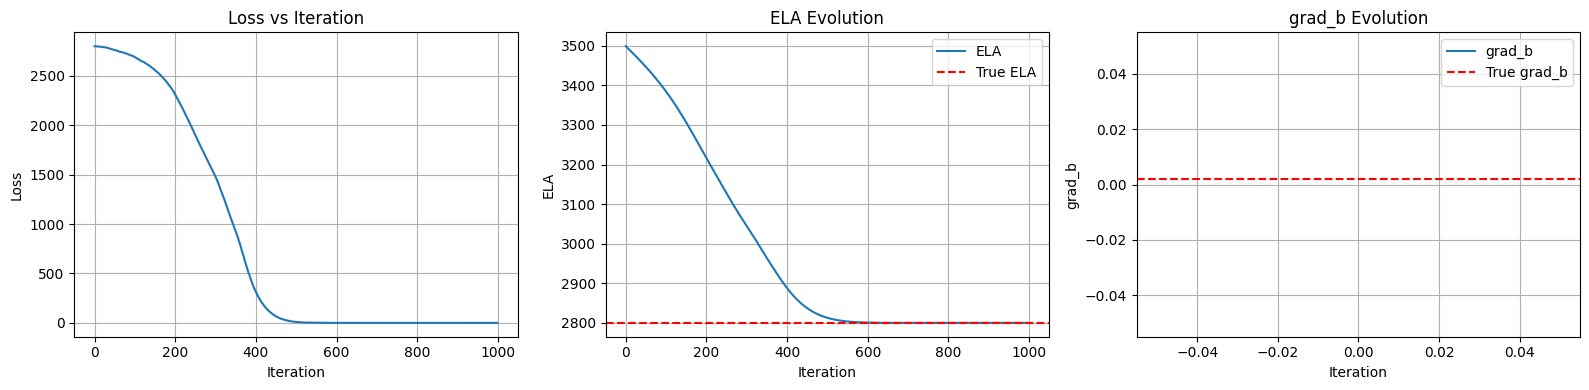

In [12]:
# Plot loss
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.plot(loss_hist)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Loss vs Iteration')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(ELA_history, label='ELA')
plt.axhline(y=ELA_true.item(), color='r', linestyle='--', label='True ELA')
plt.xlabel('Iteration')
plt.ylabel('ELA')
plt.title('ELA Evolution')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(grad_b_history, label='grad_b')
plt.axhline(y=grad_b_true.item(), color='r', linestyle='--', label='True grad_b')
plt.xlabel('Iteration')
plt.ylabel('grad_b')
plt.title('grad_b Evolution')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



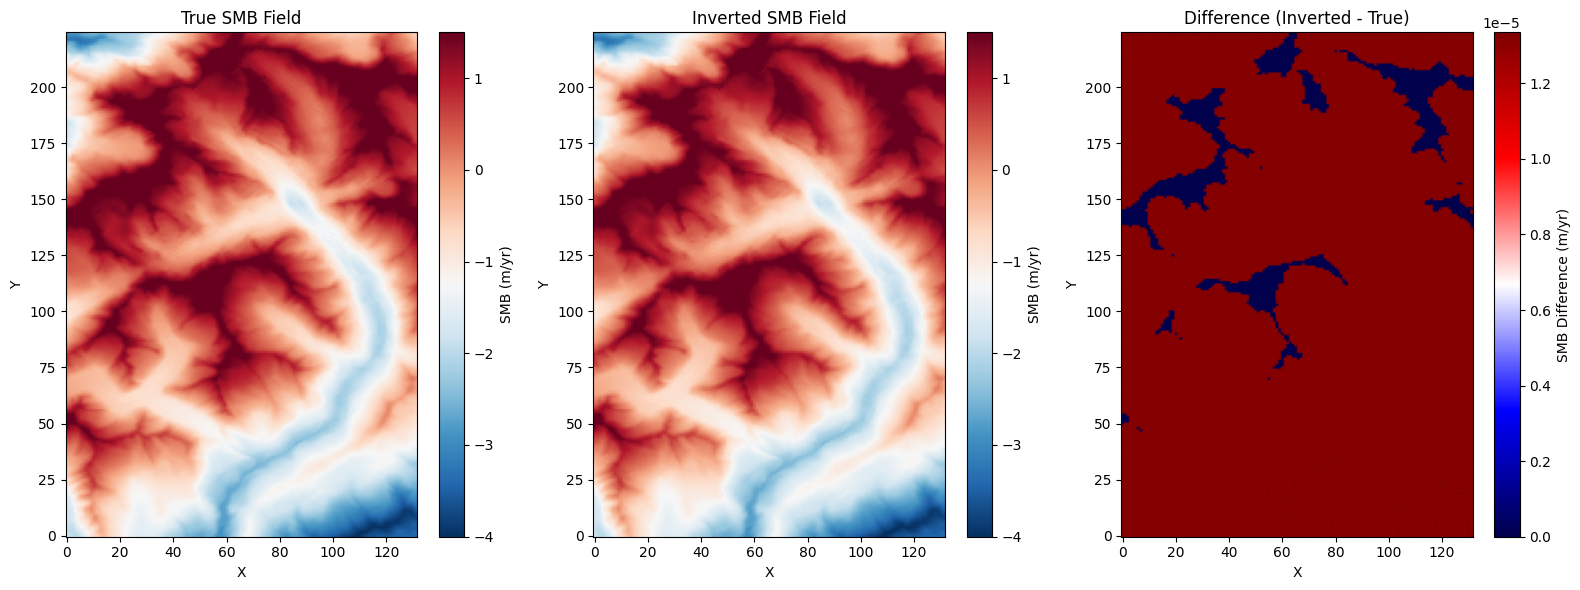


SMB Field Statistics:
True SMB - Mean: -0.1196, Std: 1.1864
Inverted SMB - Mean: -0.1196, Std: 1.1864
Difference - Mean: 0.0000, Std: 0.0000
RMSE: 0.0000


In [13]:
# Compute SMB fields
Z_topo = topo  # Using the topography grid

# True SMB field
smb_true = torch.minimum(grad_b_true * (Z_topo - ELA_true), b_max_true)

# Inverted SMB field
smb_inverted = torch.minimum(grad_b_true * (Z_topo - ELA_inv), b_max_true)

# Difference
smb_difference = smb_inverted - smb_true

# Plot the three fields
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# True SMB
im1 = axes[0].imshow(smb_true.cpu().detach().numpy(), cmap='RdBu_r', aspect='auto')
axes[0].set_title('True SMB Field')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')

plt.colorbar(im1, ax=axes[0], label='SMB (m/yr)')

# Inverted SMB
im2 = axes[1].imshow(smb_inverted.cpu().detach().numpy(), cmap='RdBu_r', aspect='auto')
axes[1].set_title('Inverted SMB Field')
axes[1].set_xlabel('X')
axes[1].set_ylabel('Y')
plt.colorbar(im2, ax=axes[1], label='SMB (m/yr)')

# Difference
im3 = axes[2].imshow(smb_difference.cpu().detach().numpy(), cmap='seismic', aspect='auto')
axes[2].set_title('Difference (Inverted - True)')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')
plt.colorbar(im3, ax=axes[2], label='SMB Difference (m/yr)')
for ax in axes:
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Print statistics
print(f"\nSMB Field Statistics:")
print(f"True SMB - Mean: {smb_true.mean().item():.4f}, Std: {smb_true.std().item():.4f}")
print(f"Inverted SMB - Mean: {smb_inverted.mean().item():.4f}, Std: {smb_inverted.std().item():.4f}")
print(f"Difference - Mean: {smb_difference.mean().item():.4f}, Std: {smb_difference.std().item():.4f}")
print(f"RMSE: {torch.sqrt((smb_difference**2).mean()).item():.4f}")
